<a href="https://colab.research.google.com/github/harimshin/data-science-portfolio/blob/main/Monitoring_Plan_Design_with_Pima_Diabetes_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### **MLOps - Model Monitoring Plan with Pima Diabetes Data**

**Objective**

This project implements a monitoring plan to detect when a deployed machine learning model may no longer be reliable, and to translate that detection into a clear, actionable response.

Models trained on historical data can degrade in production as the world they operate in changes. This project addresses that risk by monitoring three distinct signals, each answering a different question about model health:

1. **Data drift** — has the distribution of incoming input features shifted from what the model was trained on?
2. **Prediction drift** — has the distribution of the model's predicted outputs changed, even before outcomes are known?
3. **Performance drift** — has the model's actual predictive accuracy declined, once ground truth labels become available?

The first two can be checked immediately as new data arrives, while the third requires labels that are often delayed in real-world systems — a distinction this project deliberately preserves rather than treating monitoring as a single undifferentiated check.

For each type of drift, statistical tests (Kolmogorov-Smirnov, Population Stability Index) or performance metrics are compared against defined warning and critical thresholds, each paired with a specific recommended action. The goal is a monitoring framework where detecting drift is directly connected to a decision — investigate, alert, or retrain — rather than producing a metric with no consequence attached.

**1. Data preparation**

In [1]:
import pandas as pd

column_names = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DPF", "Age", "Outcome"
]
df = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv', names=column_names)

In [2]:
df.shape

(768, 9)

In [3]:
target_col = 'Outcome'
feature_cols = [col for col in df.columns if col != target_col]

**2. Exploratory Data Analysis (EDA) & Data Imputation**

In [4]:
class_dist = df[target_col].value_counts(normalize=True).round(4)
print(class_dist)

Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

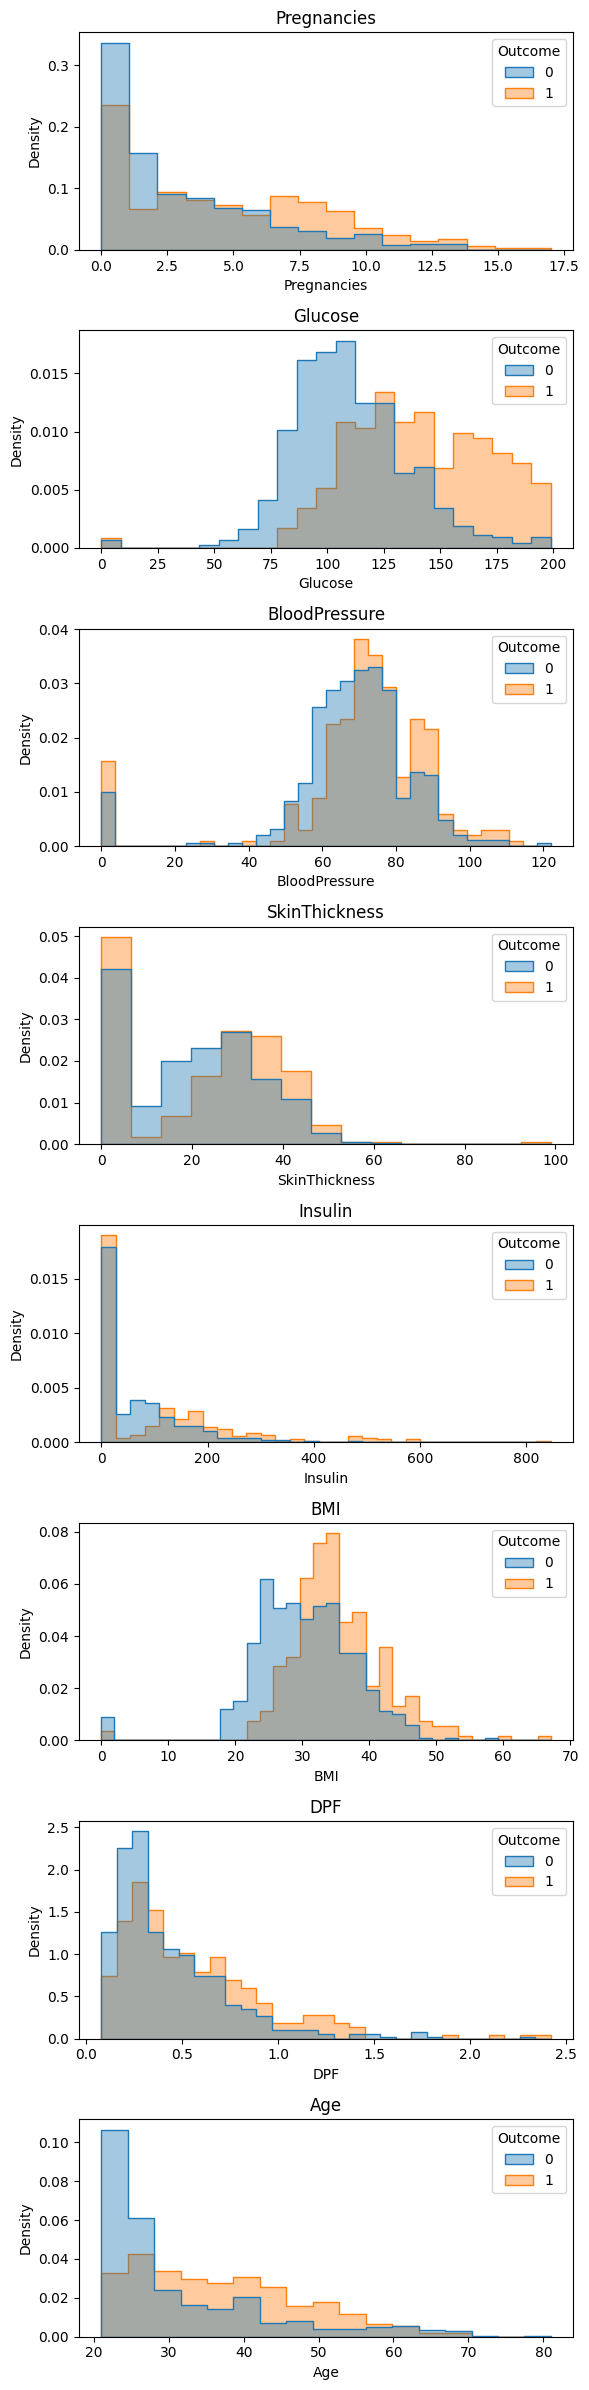

In [6]:
n = len(feature_cols)
fig, axes = plt.subplots(n, 1, figsize=(6, 3*n))

for ax, col in zip(axes, feature_cols):
    sns.histplot(
        data=df,
        x=col,
        hue=target_col,
        stat='density',
        common_norm=False,
        element='step',
        alpha=0.4,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

`Glucose`, `BMI`, `Age`, and `Pregnancies` show the clearest separation between diabetic and non-diabetic patients, making them likely strong predictors — higher glucose levels, higher body mass, older age, and more pregnancies are all associated with elevated diabetes risk. On the other hand, `BloodPressure`, `SkinThickness`, and `DPF` overlap more heavily between classes, suggesting weaker individual predictive power. Several features (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`) also show suspicious spikes at 0, likely representing missing values rather than true measurements, and should be cleaned before modeling.

In [7]:
df_imputed = df.copy()

In [8]:
import numpy as np

missing_cols = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df_imputed[missing_cols] = df_imputed[missing_cols].replace(0, np.nan)
missing_props = df_imputed[missing_cols].isna().mean().round(4)

print(missing_props)

Glucose          0.0065
BloodPressure    0.0456
SkinThickness    0.2956
Insulin          0.4870
BMI              0.0143
dtype: float64


In [9]:
high_missing_cols = missing_props[missing_props > 0.10].index.tolist()

print("High-missing columns (>10%):", high_missing_cols)

High-missing columns (>10%): ['SkinThickness', 'Insulin']


In [10]:
for col in high_missing_cols:
    df_imputed[f'{col}_missing'] = df_imputed[col].isna().astype(int)

for col in missing_cols:
    df_imputed[col] = (
        df_imputed
        .groupby(target_col)[col]
        .transform(lambda x: x.fillna(x.median()))
    )

flag_cols = [f'{col}_missing' for col in high_missing_cols]
flagged_missing = df_imputed[flag_cols].sum()
print(flagged_missing)

SkinThickness_missing    227
Insulin_missing          374
dtype: int64


The correlation heatmap computed after imputation shows mostly weak-to-moderate relationships among the features, with no signs of severe multicollinearity. The strongest correlation is between `SkinThickness` and `BMI` (0.57), likely reflecting shared associations with body fat. `Pregnancies` and `Age` follow closely (0.54), which makes intuitive sense — older individuals have had more opportunities to become pregnant. `Glucose` and `Insulin` also show a moderate positive correlation (0.49), consistent with insulin's role in regulating blood glucose. Most other feature pairs — such as `DPF` with the other variables, or `BMI` with `Age` — remain near zero, indicating they carry largely independent information. Overall, since no pair exceeds ~0.6, multicollinearity isn't a major concern for modeling, and each feature likely contributes some unique signal toward predicting the diabetes outcome.

**4. Model**

*4-1. Gradient Boosting with Hyperparameter Tuning*

In [11]:
pip install scikit-learn

In [12]:
X = df_imputed[feature_cols + flag_cols]
y = df_imputed[target_col]

print("Dimension of X:", X.shape)
print("Dimension of y:", y.shape)

Dimension of X: (768, 10)
Dimension of y: (768,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

In [14]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}

gb = GradientBoostingClassifier(random_state = 42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_cv = GridSearchCV(
    estimator=gb,
    param_grid=param_grid,
    cv=cv,
    scoring = 'roc_auc',
    n_jobs=-1
)

gb_cv_model = gb_cv.fit(X_train, y_train)

best_params = gb_cv_model.best_params_
best_model = gb_cv_model.best_estimator_

y_proba_best = best_model.predict_proba(X_test)[:, 1]
roc_auc_best = roc_auc_score(y_test, y_proba_best)

print("Best Parameters:", best_params)
print(f"ROC-AUC: {roc_auc_best:.4f}")

Best Parameters: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
ROC-AUC: 0.9375


*4-2. Featue Impotance*

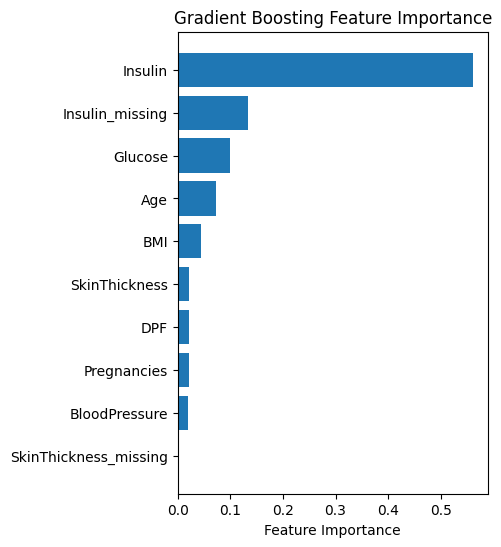

In [15]:
feature_importance = best_model.feature_importances_
sorted_idx = np.argsort(feature_importance)

plt.figure(figsize=(4, 6))
plt.barh(range(X.shape[1]), feature_importance[sorted_idx], align='center')
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Feature Importance")
plt.title("Gradient Boosting Feature Importance")
plt.show()

The Gradient Boosting feature importance plot reveals that `Insulin` is by far the dominant predictor, accounting for over 55% of total importance — substantially more than any other feature. Interestingly, the `Insulin_missing` flag ranks as the second most important feature, suggesting that whether a patient's insulin level was recorded (or missing) carries meaningful predictive signal on its own, independent of the imputed value. `Glucose` and `Age` follow as moderately important predictors, consistent with the earlier EDA showing clear distributional separation by outcome. The remaining features — `BMI`, `SkinThickness`, `DPF`, `Pregnancies`, and `BloodPressure` — contribute relatively little individually, each below 0.05 importance, while `SkinThickness_missing` shows essentially no importance, indicating that missingness in that column isn't informative for predicting diabetes.

Overall, the model relies heavily on `Insulin` and its missingness pattern, which may warrant further investigation into why this feature so strongly dominates — including checking for potential data leakage or over-reliance on imputed values.

**5. Monitoring Plan**

*5-1. Data Drift*

Data drift refers to changes in the statistical properties of input data over time that can degrade the performance of machine learning models. This drift can occur because the underlying real-world processes that generate the data may change, making previously learned patterns or relationships less relevant.

a. Synthetic Data Generation

Synthetic data was generated using a Gaussian Multivariate Copula by first fitting it to the original dataset to capture feature marginals and correlations, then sampling reference data from this baseline copula.


In [16]:
pip install copulas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 2.0 MB/s eta 0:00:00


In [17]:
from copulas.multivariate import GaussianMultivariate
from sklearn.linear_model import LogisticRegression

def generate_synthetic_data(
    df,
    target_col,
    n_samples=None,
    random_state=42
):

    df = df.copy()

    if n_samples is None:
        n_samples = len(df)

    np.random.seed(random_state)

    X = df.drop(columns=target_col)
    y = df[target_col]

    if y.nunique() != 2:
        raise ValueError("Target must be binary.")

    copula = GaussianMultivariate()
    copula.fit(X)

    X_synthetic = copula.sample(n_samples)

    lr_model = LogisticRegression(
        max_iter=1000,
        random_state=random_state
    )

    lr_model.fit(X, y)

    y_probs = lr_model.predict_proba(
        X_synthetic
    )[:, 1]

    y_synthetic = np.random.binomial(
        1,
        y_probs
    )

    df_synthetic = X_synthetic.copy()
    df_synthetic[target_col] = y_synthetic

    return df_synthetic

In [18]:
df_synthetic = generate_synthetic_data(
    df,
    target_col,
    n_samples=len(df)
)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:796: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:796: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:801: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  a, b = optimize.fsolve(func, (1.0, 1.0))
/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:796: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:801: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the 

In [19]:
df_synthetic_imputed = df_synthetic.copy()

In [20]:
df_synthetic_imputed[missing_cols] = df_synthetic_imputed[missing_cols].replace(0, np.nan)

for col in high_missing_cols:
    df_synthetic_imputed[f'{col}_missing'] = (
        df_synthetic_imputed[col]
          .isna()
          .astype(int)
    )

for col in missing_cols:
    df_synthetic_imputed[col] = (
        df_synthetic_imputed
        .groupby(target_col)[col]
        .transform(lambda x: x.fillna(x.median()))
    )

`df_imputed` was assigned to `df_ref` to serve as the reference (baseline) dataset, while `df_synthetic_imputed` was assigned to `df_new` to represent the comparison dataset, enabling both to be used as inputs for the subsequent drift detection test.

In [21]:
df_ref = df_imputed.copy()
df_new = df_synthetic_imputed.copy()

a. Kolmogorov-Smirnov(KS) test

The Kolmogorov–Smirnov (KS) test is a non-parametric statistical test that compares the cumulative distribution functions of two samples to determine whether they come from the same underlying distribution, without assuming any specific distributional form; it is well-suited for data drift detection because it can sensitively detect shifts in the shape, location, or spread of a feature's distribution between a reference dataset and new incoming data, flagging potential drift when the resulting p-value falls below a chosen significance threshold.


In [22]:
from scipy.stats import ks_2samp

def ks_test(df_ref, df_new, target_col, feature_cols, alpha=0.05):

    df_ref = df_ref.copy()
    df_new = df_new.copy()

    X_ref = df_ref[feature_cols]
    X_new = df_new[feature_cols]

    results = []

    for col in feature_cols:
        statistic, p_value = ks_2samp(
            X_ref[col].dropna(),
            X_new[col].dropna()
        )

        results.append({
            "feature": col,
            "KS stat": statistic,
            "p-value": p_value,
            "data drift": (
                "significant" if p_value < alpha else "not significant"
            )
        })

    results_df = pd.DataFrame(results)

    return results_df

In [23]:
ks_results_df = ks_test(df_ref, df_new, target_col, feature_cols)
print(ks_results_df.round(4))

         feature  KS stat  p-value       data drift
0    Pregnancies   0.1081   0.0003      significant
1        Glucose   0.0443   0.4393  not significant
2  BloodPressure   0.1055   0.0004      significant
3  SkinThickness   0.3398   0.0000      significant
4        Insulin   0.3646   0.0000      significant
5            BMI   0.0430   0.4778  not significant
6            DPF   0.0742   0.0291      significant
7            Age   0.0924   0.0028      significant


The KS test results show significant drift in most features between the reference and new datasets, with `Pregnancies`, `BloodPressure`, `SkinThickness`, `Insulin`, `DPF`, and `Age` all yielding p-values below the 0.05 threshold, while `Glucose` and `BMI` showed no significant drift. Notably, `SkinThickness` and `Insulin` exhibited the largest KS statistics (0.3398 and 0.3646, respectively) with p-values of essentially 0, indicating substantial distributional shifts in these features.

It's worth noting that KS p-values are highly sensitive to sample size — with larger datasets, even small, practically negligible differences between distributions can produce very low p-values, so the KS statistic itself should be considered alongside the p-value to gauge the practical magnitude of drift, rather than relying on statistical significance alone.

b. Population Stability Index (PSI)

The Population Stability Index (PSI) is a metric that quantifies how much a variable's distribution has shifted between two datasets by binning the data and comparing the proportion of observations in each bin, and it is widely used for data drift detection because it provides a single, interpretable score (typically with thresholds like < 0.1 for no significant drift, 0.1–0.25 for moderate drift, and > 0.25 for major drift) that is less sensitive to sample size than statistical significance tests like the KS test, making it practical for monitoring drift magnitude in production settings.

In [24]:
def calculate_psi(expected, actual, buckets=10, epsilon=1e-4):

    expected = pd.Series(expected).dropna().to_numpy()
    actual = pd.Series(actual).dropna().to_numpy()

    if len(expected) == 0 or len(actual) == 0:
        return np.nan

    breakpoints = np.quantile(
        expected,
        np.linspace(0, 1, buckets + 1)
    )

    breakpoints = np.unique(breakpoints)

    expected_pct = (
        np.histogram(expected, bins=breakpoints)[0] / len(expected)
    )

    actual_pct = (
        np.histogram(actual, bins=breakpoints)[0] / len(actual)
    )

    expected_pct = np.clip(expected_pct, epsilon, None)
    actual_pct = np.clip(actual_pct, epsilon, None)

    psi = np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )

    return psi

In [25]:
def psi_results(df_ref, df_new, feature_cols, buckets=10):

    X_ref = df_ref[feature_cols]
    X_new = df_new[feature_cols]

    psi_results = []

    for col in feature_cols:

        psi = calculate_psi(
            X[col],
            X_new[col],
            buckets=buckets
        )

        psi_results.append({
            "feature": col,
            "PSI": psi,
            "data drift": (
                "significant" if psi > 0.25
                else "moderately significant" if psi > 0.10
                else "not significant"
            )
        })

    psi_results_df = pd.DataFrame(psi_results)

    return psi_results_df

In [26]:
psi_results_df = psi_results(
    df_ref,
    df_new,
    feature_cols,
    buckets=10
)

print(psi_results_df.round(4))

         feature     PSI       data drift
0    Pregnancies  0.0156  not significant
1        Glucose  0.0020  not significant
2  BloodPressure  0.0925  not significant
3  SkinThickness  0.6717      significant
4        Insulin  0.5034      significant
5            BMI  0.0150  not significant
6            DPF  0.0344  not significant
7            Age  0.0670  not significant


The PSI results largely align with the KS test on the most significant drifts, both flagging `SkinThickness` (0.6717) and `Insulin` (0.5034) as major drift, but otherwise diverge: PSI classifies the remaining six features as stable (all below 0.1), while the KS test had flagged several of these — including `Pregnancies`, `BloodPressure`, `DPF`, and `Age` — as significant. This difference reflects PSI's focus on the magnitude of distributional change rather than statistical significance, making it less sensitive to sample size and better suited for judging the practical impact of drift, while the KS test's p-values can flag small but statistically significant shifts. Together, both methods confirm `SkinThickness` and `Insulin` as the features with the most pronounced drift.

In [27]:
import textwrap

def summarize_data_drift(
    ks_results_df,
    psi_results_df,
    feature_col='feature',
    width=80):
    """
    One-line summary: which features are flagged by KS and/or PSI,
    ranked by severity. Assumes ks_results_df and psi_results_df
    are already shown separately — this just adds the 'so what'.
    """
    ks_flagged = set(
        ks_results_df.loc[ks_results_df['p-value'] < 0.05, feature_col]
    )
    psi_flagged = set(
        psi_results_df.loc[psi_results_df['PSI'] > 0.10, feature_col]
    )

    all_features = (
        set(ks_results_df[feature_col]) | set(psi_results_df[feature_col])
    )

    both = ks_flagged & psi_flagged
    ks_only = ks_flagged - psi_flagged
    psi_only = psi_flagged - ks_flagged
    unflagged = all_features - (ks_flagged | psi_flagged)

    groups = [
        ('CRITICAL', 'Flagged by both KS and PSI', both),
        ('WARNING', 'Flagged by KS only', ks_only),
        ('WARNING', 'Flagged by PSI only', psi_only),
        ('OK', 'Not flagged', unflagged),
    ]

    actions = {
    'CRITICAL': 'Alert, escalate for review, consider retrain/rollback.',
    'WARNING': 'Log and monitor closely; investigate if it persists.',
    'OK': 'No action required.'
    }

    for severity, label, features in groups:
        if features:
            print(textwrap.fill(
                f"[{severity}] {label} ({len(features)}): {sorted(features)}",
                width=width)
            )
            print(textwrap.fill(f"Action: {actions[severity]}", width=width))
            print()


In [28]:
summarize_data_drift(ks_results_df, psi_results_df)

[CRITICAL] Flagged by both KS and PSI (2): ['Insulin', 'SkinThickness']
Action: Alert, escalate for review, consider retrain/rollback.

[WARNING] Flagged by KS only (4): ['Age', 'BloodPressure', 'DPF', 'Pregnancies']
Action: Log and monitor closely; investigate if it persists.

[OK] Not flagged (2): ['BMI', 'Glucose']
Action: No action required.



*5-2. Prediction Drift*

Prediction drift refers to a significant shift in the distribution of a model's predicted outputs over time, even though the model itself hasn't changed. It is particularly useful when ground-truth labels aren't yet available, serving as an early proxy signal for potential data or concept drift that could affect model performance, allowing teams to investigate and act — through retraining or rollback — before the drift impacts real-world outcomes.

In [29]:
def evaluate_prediction_drift(model, df_ref, df_new, target_col):

    X_ref = df_ref.drop(columns=[target_col])
    X_new = df_new.drop(columns=[target_col])

    proba_ref = model.predict_proba(X_ref)[:, 1]
    proba_new = model.predict_proba(X_new)[:, 1]

    ks_stat, ks_pvalue = ks_2samp(proba_ref, proba_new)
    psi_value = calculate_psi(proba_ref, proba_new)

    if ks_pvalue <= 0.01:
        ks_severity = 'CRITICAL'
    elif ks_pvalue <= 0.05:
        ks_severity = 'WARNING'
    else:
        ks_severity = 'OK'

    if psi_value >= 0.25:
        psi_severity = 'CRITICAL'
    elif psi_value >= 0.10:
        psi_severity = 'WARNING'
    else:
        psi_severity = 'OK'

    actions = {
        'OK': 'No action needed.',
        'WARNING': 'Log and monitor closely; investigate if it persists.',
        'CRITICAL': 'Alert, escalate for review, consider retrain/rollback.'
    }

    order = {'CRITICAL': 0, 'WARNING': 1, 'OK': 2}

    print(f"[{ks_severity}] KS test on predicted probability "
          f"(p-value = {ks_pvalue:.4f})")
    print(f"Action: {actions[ks_severity]}")
    print()
    print(f"[{psi_severity}] PSI on predicted probability "
          f"(PSI = {psi_value:.4f})")
    print(f"Action: {actions[psi_severity]}")

In [30]:
evaluate_prediction_drift(best_model, df_ref, df_new, target_col)

[CRITICAL] KS test on predicted probability (p-value = 0.0000)
Action: Alert, escalate for review, consider retrain/rollback.

[CRITICAL] PSI on predicted probability (PSI = 2.2273)
Action: Alert, escalate for review, consider retrain/rollback.


Both the KS test (p-value = 0.0000, below the 0.05 significance threshold) and PSI (2.2273, far exceeding the 0.25 major-drift threshold) on the predicted probabilities indicate critical prediction drift, triggering an alert, escalation for review, and consideration of model retraining or rollback.

*5-3. Performance Drift*

Performance drift refers to a measurable decline in a model's predictive accuracy or other performance metrics (e.g., precision, recall, F1-score) over time, typically identified once ground-truth labels become available for comparison against the model's predictions. It is monitored because it provides the most direct evidence of whether a model is still effective in production, capturing the real-world impact of any underlying data or concept drift rather than relying on proxy signals alone. Detecting performance drift allows teams to confirm whether earlier warnings from data or prediction drift translated into actual degradation, guiding decisions on retraining, rollback, or further investigation.

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_datasets(
    datasets,
    best_model,
    target_col=target_col,
    test_size=0.3,
    random_state=42
):

    evaluation_results = []

    for name, data in datasets.items():
        X = data.drop([target_col], axis=1)
        y = data[target_col]

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )

        y_proba_best = best_model.predict_proba(X_test)[:, 1]
        y_pred_best = best_model.predict(X_test)

        evaluation_results.append({
            "Dataset": name,
            "AUC": roc_auc_score(y_test, y_proba_best),
            "Accuracy": accuracy_score(y_test, y_pred_best),
            "Precision": precision_score(y_test, y_pred_best),
            "Recall": recall_score(y_test, y_pred_best),
            "F1 Score": f1_score(y_test, y_pred_best)
        })

    evaluation_results_df = pd.DataFrame(evaluation_results)

    return evaluation_results_df

In [32]:
datasets = {
    "Reference": df_ref,
    "New": df_new
}

evaluation_results_df = evaluate_datasets(
    datasets,
    best_model,
    target_col,
    test_size=0.3,
    random_state=42
)

In [33]:
print(evaluation_results_df.round(4))

     Dataset     AUC  Accuracy  Precision  Recall  F1 Score
0  Reference  0.9375    0.8745     0.8493  0.7750    0.8105
1        New  0.7978    0.7749     0.7391  0.4595    0.5667


In [34]:
def compute_metric_drops(
    evaluation_results_df,
    ref_label='Reference',
    new_label='New',
    dataset_col='Dataset'
):

    df = evaluation_results_df.set_index(dataset_col)

    metric_drop_row = df.loc['Reference'] - df.loc['New']
    metric_drop_row.name = 'Drop'

    metric_drop_result_df = pd.concat([df, metric_drop_row.to_frame().T])

    return metric_drop_result_df

In [35]:
metrics_drops_df = compute_metric_drops(evaluation_results_df)
print(metrics_drops_df.round(4))

              AUC  Accuracy  Precision  Recall  F1 Score
Reference  0.9375    0.8745     0.8493  0.7750    0.8105
New        0.7978    0.7749     0.7391  0.4595    0.5667
Drop       0.1398    0.0996     0.1102  0.3155    0.2438


The performance metrics reveal a substantial decline across the board when comparing the new dataset to the reference: AUC dropped by 0.1398 (from 0.9375 to 0.7978) and accuracy fell by nearly 10 percentage points (0.8745 to 0.7749). The most pronounced degradation is in recall, which dropped by 0.3155 (from 0.7750 to 0.4595), indicating the model is now missing a significantly larger proportion of positive cases, while precision and F1-score also declined by 0.1102 and 0.2438, respectively.

This consistent and sizable drop across all metrics confirms that the earlier data and prediction drift signals have translated into real performance degradation, warranting model retraining or rollback.